<a href="https://colab.research.google.com/github/NadaLajili-cloud/KNN-UCI-Credit-Card-Default/blob/main/Mini_Proj_KNN_UCI_Credit_Card.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 **Prétraitement et KNN sur UCI Credit Card Default**

**Jeu de données :** 30 000 clients d'une banque taïwanaise (2005), 23 variables explicatives, cible `default.payment.next.month` (1 = défaut de paiement le mois suivant).

**Plan** (mêmes étapes que TP1 et TP2, sur une nouvelle base)
1. Importation et exploration
2. Nettoyage : manquants, doublons, aberrantes, encodage
3. Normalisation / standardisation sans fuite de données
4. KNN classification (défaut de paiement)
5. KNN régression (prédire `LIMIT_BAL`, le plafond de crédit)
6. Pour aller plus loin : normalisation, Manhattan, pondération
7. Questions de cours

# 0. Importation des bibliothèques

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, classification_report,
                             ConfusionMatrixDisplay, root_mean_squared_error, r2_score)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# 1. Importer la base (Google Colab)

Exécuter **une seule** des trois méthodes. Le fichier est `UCI_Credit_Card.csv` (Kaggle : *Default of Credit Card Clients Dataset*).

In [ ]:
# Méthode 3 — Téléversement direct (le fichier disparaît à la fin de la session Colab)
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('UCI_Credit_Card.csv')

# Méthode 1 — Monter Google Drive (le fichier reste dans le Drive)
# from google.colab import drive
# drive.mount('/content/drive')
# df = pd.read_csv('/content/drive/MyDrive/TP_ML/UCI_Credit_Card.csv')

# Méthode 2 — gdown
# !pip install -q gdown
# import gdown
# file_id = '...'   # à compléter
# gdown.download(f'https://drive.google.com/uc?id={file_id}', 'UCI_Credit_Card.csv', quiet=False)
# df = pd.read_csv('UCI_Credit_Card.csv')

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


**Monter le Drive** : le fichier reste stocké dans le Drive, il survit à la session. **Téléverser** : le fichier est copié dans le stockage temporaire de Colab et est supprimé à la fin de la session.

# 2. Exploration et nettoyage
## 2.1 Explorer la base

In [ ]:
print("Dimensions :", df.shape)
df.info()

Dimensions : (30000, 25)
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2        

In [ ]:
df.describe(include='all').T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.50,8660.40,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0


**Réponse 2.1.** La base contient 30 000 lignes et 25 colonnes. Toutes sont numériques (`int64`/`float64`), mais plusieurs sont **en réalité catégorielles** :
- `SEX` (1 = homme, 2 = femme), `EDUCATION` (1 = master, 2 = université, 3 = lycée, 4 = autre), `MARRIAGE` (1 = marié, 2 = célibataire, 3 = autre) : ce sont des codes, pas des quantités ;
- `default.payment.next.month` : cible binaire ;
- `PAY_0`…`PAY_6` : statut de remboursement, **ordinal** (-1 = payé à temps, 1 = 1 mois de retard, …), à garder numérique.

## 2.2 Valeurs manquantes

In [ ]:
manquants = df.isnull().sum()
pourcentage = (manquants / len(df) * 100).round(2)
pd.DataFrame({'manquants': manquants, '%': pourcentage}).sort_values('%', ascending=False).head(10)

,manquants,%
ID,0,0.0
LIMIT_BAL,0,0.0
SEX,0,0.0
EDUCATION,0,0.0
MARRIAGE,0,0.0
AGE,0,0.0
PAY_0,0,0.0
PAY_2,0,0.0
PAY_3,0,0.0
PAY_4,0,0.0


In [ ]:
print('Total manquants :', df.isnull().sum().sum())

Total manquants : 0


**Réponse 2.2.** Cette base ne contient **aucune valeur manquante** (total = 0), donc pas d'imputation nécessaire. Si c'était le cas : on supprimerait une colonne très incomplète et on imputerait les autres par la **médiane** (robuste aux valeurs extrêmes, contrairement à la moyenne) ou le **mode** (variables catégorielles), calculés sur le train uniquement.

En revanche, il y a des **valeurs non documentées** : `EDUCATION` ∈ {0, 5, 6} et `MARRIAGE` = 0. On les regroupe dans « autre ».

In [ ]:
print(df['EDUCATION'].value_counts().sort_index(), '\n')
print(df['MARRIAGE'].value_counts().sort_index())

df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})   # -> 4 = autre
df['MARRIAGE']  = df['MARRIAGE'].replace({0: 3})                # -> 3 = autre

# noms de colonnes plus propres
df = df.rename(columns={'default.payment.next.month': 'default', 'PAY_0': 'PAY_1'})

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64 

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


## 2.3 Doublons et colonnes inutiles

In [ ]:
print("Lignes dupliquées (hors ID) :", df.drop(columns='ID').duplicated().sum())
print("ID uniques :", df['ID'].is_unique)

Lignes dupliquées (hors ID) : 35
ID uniques : True


In [ ]:
df = df.drop_duplicates(subset=df.columns.drop('ID'))
df = df.drop(columns=['ID'])
print(df.shape)
df.head()

(29965, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


**Réponse 2.3.** `ID` est un simple identifiant : il ne contient aucune information sur le comportement de paiement, et le garder pourrait fausser les distances de KNN. On retire aussi les doublons (clients identiques sur toutes les variables) pour ne pas compter deux fois la même information. Ici on trouve **35 lignes dupliquées** : la base passe de 30 000 à **29 965 clients** et de 25 à 24 colonnes (sans `ID`).

## 2.4 Valeurs aberrantes (méthode IQR) — colonne `LIMIT_BAL`

Q1=50000  Q3=240000  IQR=190000  bornes=[-235000 ; 525000]
Valeurs aberrantes : 167 (0.56 % de la base)


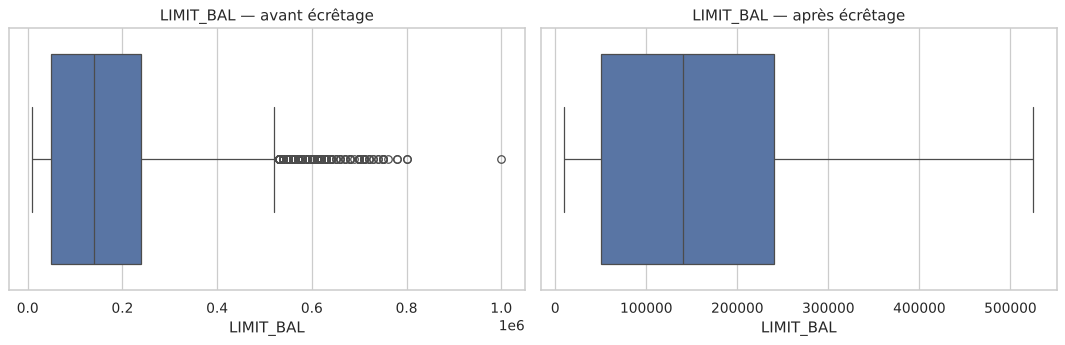

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['LIMIT_BAL'], ax=axes[0]).set_title('LIMIT_BAL — avant écrêtage')

Q1, Q3 = df['LIMIT_BAL'].quantile([0.25, 0.75])
IQR = Q3 - Q1
borne_inf, borne_sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
nb_outliers = ((df['LIMIT_BAL'] < borne_inf) | (df['LIMIT_BAL'] > borne_sup)).sum()
print(f"Q1={Q1:.0f}  Q3={Q3:.0f}  IQR={IQR:.0f}  bornes=[{borne_inf:.0f} ; {borne_sup:.0f}]")
print(f"Valeurs aberrantes : {nb_outliers} ({nb_outliers/len(df)*100:.2f} % de la base)")

df['LIMIT_BAL'] = df['LIMIT_BAL'].clip(borne_inf, borne_sup)
sns.boxplot(x=df['LIMIT_BAL'], ax=axes[1]).set_title('LIMIT_BAL — après écrêtage')
plt.tight_layout(); plt.show()

**Réponse 2.4.** *Supprimer* retire les lignes concernées (perte d'information, et de clients). *Écrêter* (`clip`) garde les lignes mais ramène la valeur à la borne. Ici l'écrêtage est préférable : ce sont de vrais clients à fort plafond de crédit (pas des erreurs), et la proportion concernée est faible mais non négligeable. **Chiffres obtenus :** Q1 = 50 000, Q3 = 240 000, IQR = 190 000, bornes = [−235 000 ; 525 000]. La borne basse est négative : seuls les **plafonds élevés** sont concernés, soit **167 clients (0,56 %)**, ramenés à 525 000 (le max initial était 1 000 000). Pour rester rigoureux, les bornes devraient être calculées sur le train seul ; elles sont calculées ici sur toute la base par simplification, comme dans le TP1.

## 2.5 Encodage des variables catégorielles

In [ ]:
df['SEX'] = df['SEX'].map({1: 0, 2: 1})            # 0 = homme, 1 = femme
df = pd.get_dummies(df, columns=['EDUCATION', 'MARRIAGE'], drop_first=True, dtype=int)
print(df.shape)
df.head()

(29965, 27)


,LIMIT_BAL,SEX,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
0,20000.0,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1,1,0,0,0,0
1,120000.0,1,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1,1,0,0,1,0
2,90000.0,1,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0,1,0,0,1,0
3,50000.0,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0,1,0,0,0,0
4,50000.0,0,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0,1,0,0,0,0


**Réponse 2.5.** `SEX` n'a que deux modalités : un codage 0/1 suffit. `EDUCATION` et `MARRIAGE` n'ont **pas d'ordre naturel** : un codage 1, 2, 3 ferait croire à KNN qu'« autre » est « plus loin » de « master » que « université ». Le One-Hot Encoding évite ce biais. `drop_first=True` supprime une colonne redondante (colinéarité) : la modalité supprimée (`EDUCATION = 1`, `MARRIAGE = 1`) est représentée par des 0 dans toutes les colonnes restantes.

# 3. Normalisation et standardisation

**Séparer d'abord, normaliser ensuite** : `fit` sur le train uniquement.

In [ ]:
X = df.drop(columns='default')
y = df['default']

print("Répartition de la cible :\n", y.value_counts(normalize=True).round(3))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

Répartition de la cible :
 default
0    0.779
1    0.221
Name: proportion, dtype: float64


La classe « défaut » ne représente qu'environ 22 % des clients : un modèle qui prédit toujours « pas de défaut » aurait déjà ~78 % d'exactitude. On utilise donc un découpage **stratifié** et on suivra aussi le **F1** et le **rappel** de la classe défaut.

In [ ]:
cols = ['LIMIT_BAL', 'AGE'] + [c for c in X.columns if c.startswith(('BILL_AMT', 'PAY_AMT'))]

# Min-Max
scaler_mm = MinMaxScaler()
X_train_mm, X_test_mm = X_train.copy(), X_test.copy()
X_train_mm[cols] = scaler_mm.fit_transform(X_train[cols])
X_test_mm[cols]  = scaler_mm.transform(X_test[cols])

# Standardisation
scaler_std = StandardScaler()
X_train_std, X_test_std = X_train.copy(), X_test.copy()
X_train_std[cols] = scaler_std.fit_transform(X_train[cols])
X_test_std[cols]  = scaler_std.transform(X_test[cols])

display(X_train_mm[cols].describe().loc[['min', 'max']].round(2))
display(X_train_std[cols].describe().loc[['mean', 'std']].round(2))
display(X_test_mm[cols].describe().loc[['min', 'max']].round(2))

,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
mean,-0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
min,0.0,0.00,0.13,0.00,0.06,-0.09,-0.02,0.19,0.00,0.00,0.00,0.00,0.00,0.00
max,1.0,1.07,0.81,0.77,0.47,0.65,0.66,0.66,0.46,0.23,0.41,0.85,1.02,0.84


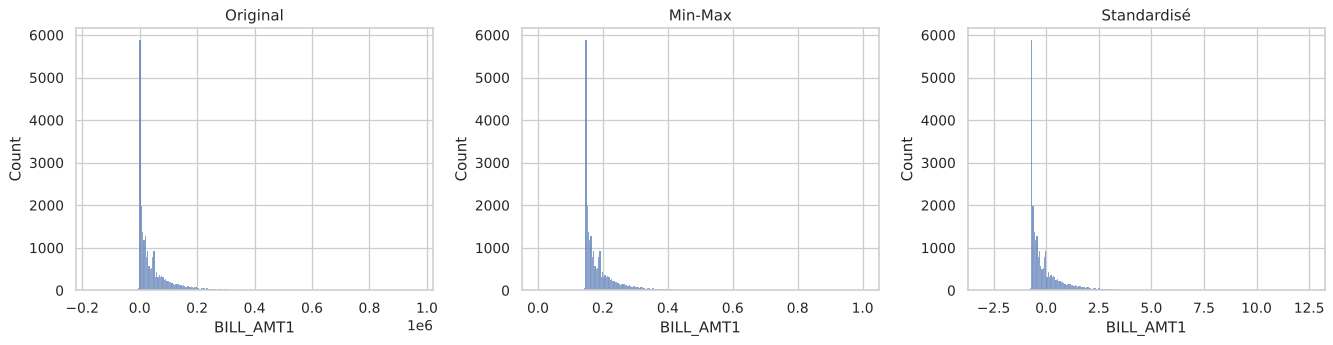

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(X_train['BILL_AMT1'], ax=axes[0]).set_title('Original')
sns.histplot(X_train_mm['BILL_AMT1'], ax=axes[1]).set_title('Min-Max')
sns.histplot(X_train_std['BILL_AMT1'], ax=axes[2]).set_title('Standardisé')
plt.tight_layout(); plt.show()

**Réponse 3.1.** On ajuste (`fit`) le scaler sur le train seul, puis on applique `transform` au test : sinon les statistiques du test (min, max, moyenne) influencent le prétraitement, c'est la **fuite de données (*data leakage*)**, qui rend l'évaluation trop optimiste. Conséquence : le test peut contenir des valeurs **hors de [0, 1]**. C'est bien ce qu'on observe ici : `AGE` va jusqu'à 1,07, `PAY_AMT5` jusqu'à 1,02 et `BILL_AMT4` descend à −0,09, car certains clients du test dépassent les extrêmes du train. C'est normal, et c'est la preuve qu'on n'a pas « triché » en regardant le test.

**Réponse 3.2.** La **forme** de la distribution ne change pas (même asymétrie), seuls **l'échelle et la position** changent : Min-Max ramène l'axe dans [0, 1], la standardisation le centre en 0 avec un écart-type de 1.

# 4. KNN pour la classification (défaut de paiement)

## 4.1 Rappel théorique
1. Choisir K. 2. Calculer les distances (euclidienne, Manhattan…) entre le nouveau client et tous les clients d'entraînement. 3. Garder les K plus proches. 4. Vote majoritaire (classification) ou moyenne (régression). 5. La prédiction est la classe majoritaire (ou la moyenne).

KNN est **paresseux** (*lazy learner*) : il n'apprend aucun modèle, il mémorise le train et fait tout le calcul à la prédiction. Sur de grands jeux de données, la prédiction est lente et gourmande en mémoire.

## 4.2 Choix de K par validation croisée
Le `Pipeline` garantit que le scaler est ajusté sur les plis d'entraînement uniquement. On garde aussi le score **train** pour repérer le surapprentissage.

In [ ]:
k_values = list(range(1, 30))

pipe_clf = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
grid_clf = GridSearchCV(pipe_clf, {'knn__n_neighbors': k_values}, cv=5,
                        scoring={'accuracy': 'accuracy', 'f1': 'f1'}, refit='accuracy',
                        return_train_score=True, n_jobs=-1)
grid_clf.fit(X_train, y_train)

best_k = grid_clf.best_params_['knn__n_neighbors']
print("Meilleur k :", best_k)
print("Exactitude moyenne CV : {:.3f}".format(grid_clf.best_score_))

Meilleur k : 15
Exactitude moyenne CV : 0.810


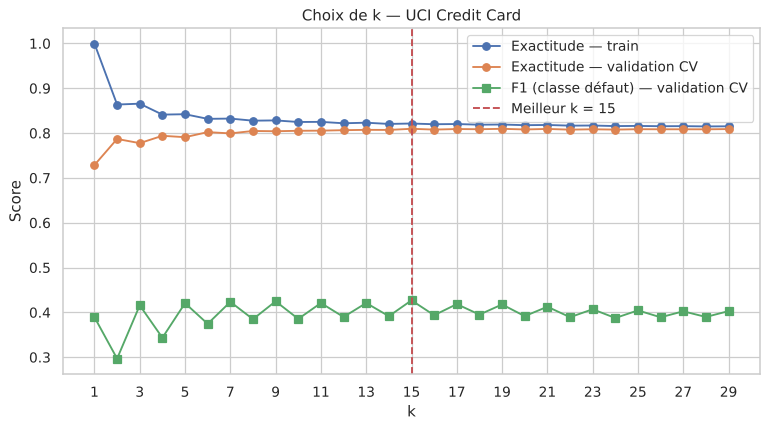

In [ ]:
r = grid_clf.cv_results_
plt.figure(figsize=(10, 5))
plt.plot(k_values, r['mean_train_accuracy'], '-o', label='Exactitude — train')
plt.plot(k_values, r['mean_test_accuracy'],  '-o', label='Exactitude — validation CV')
plt.plot(k_values, r['mean_test_f1'],        '-s', label='F1 (classe défaut) — validation CV')
plt.axvline(best_k, color='r', linestyle='--', label=f'Meilleur k = {best_k}')
plt.xlabel('k'); plt.ylabel('Score'); plt.xticks(k_values[::2])
plt.title('Choix de k — UCI Credit Card'); plt.legend(); plt.show()

## 4.3 Évaluation finale

               precision    recall  f1-score   support

pas de défaut       0.83      0.95      0.88      4667
       défaut       0.62      0.31      0.42      1326

     accuracy                           0.81      5993
    macro avg       0.73      0.63      0.65      5993
 weighted avg       0.78      0.81      0.78      5993



,Modèle,Exactitude,Rappel (défaut),F1 (défaut)
0,"Baseline (toujours ""pas de défaut"")",0.779,0.000,0.000
1,KNN k=15 — train,0.822,0.354,0.468
2,KNN k=15 — test,0.806,0.314,0.418


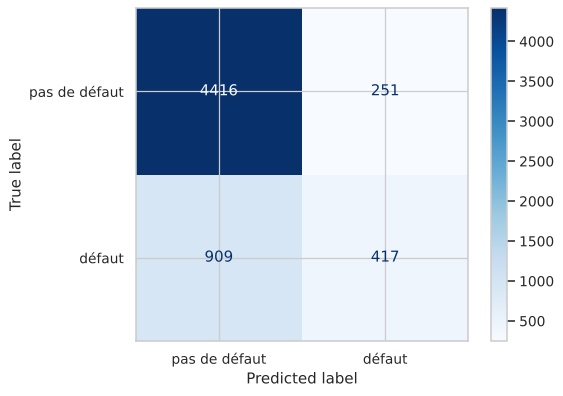

In [ ]:
best_clf = grid_clf.best_estimator_
y_train_pred, y_test_pred = best_clf.predict(X_train), best_clf.predict(X_test)

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
resultats = pd.DataFrame({
    'Modèle': ['Baseline (toujours "pas de défaut")', f'KNN k={best_k} — train', f'KNN k={best_k} — test'],
    'Exactitude': [accuracy_score(y_test, baseline.predict(X_test)),
                   accuracy_score(y_train, y_train_pred), accuracy_score(y_test, y_test_pred)],
    'Rappel (défaut)': [recall_score(y_test, baseline.predict(X_test)),
                        recall_score(y_train, y_train_pred), recall_score(y_test, y_test_pred)],
    'F1 (défaut)': [f1_score(y_test, baseline.predict(X_test)),
                    f1_score(y_train, y_train_pred), f1_score(y_test, y_test_pred)],
}).round(3)
display(resultats)
print(classification_report(y_test, y_test_pred, target_names=['pas de défaut', 'défaut']))
ConfusionMatrixDisplay.from_estimator(best_clf, X_test, y_test,
    display_labels=['pas de défaut', 'défaut'], cmap='Blues'); plt.show()

**Commentaire.**
- **Meilleur k = 15** (exactitude CV = 0,810). Exactitude : **82,2 % en train** contre **80,6 % en test** : l'écart est faible (1,6 point), donc **pas de surapprentissage marqué avec k = 15**.
- **Le surapprentissage se voit sur la courbe aux petits k** : pour k = 1, l'exactitude train vaut 1,00 mais celle de validation seulement ≈ 0,73. Plus k augmente, plus les deux courbes se rejoignent et se stabilisent vers 0,81 à partir de k ≈ 9. C'est exactement l'effet « k petit = modèle trop flexible ».
- **Mais le modèle reste peu utile** : la baseline « personne ne fait défaut » donne déjà 77,9 %, le KNN gagne seulement ~2,7 points. Sur la classe défaut : précision 0,62, **rappel 0,31**, F1 0,42. Autrement dit, **près de 7 clients sur 10 qui feront défaut ne sont pas détectés**. L'exactitude seule est trompeuse sur une base déséquilibrée.

# 5. KNN pour la régression : prédire `LIMIT_BAL`

Cible continue : le plafond de crédit. La variable `default` est conservée comme variable explicative.

In [ ]:
Xr = df.drop(columns='LIMIT_BAL')
yr = df['LIMIT_BAL']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=RANDOM_STATE)

Xr_train.describe().loc[['mean', 'std', 'min', 'max']].round(1).T.head(12)

,mean,std,min,max
SEX,0.6,0.5,0.0,1.0
AGE,35.5,9.2,21.0,79.0
PAY_1,-0.0,1.1,-2.0,8.0
PAY_2,-0.1,1.2,-2.0,8.0
PAY_3,-0.2,1.2,-2.0,8.0
PAY_4,-0.2,1.2,-2.0,8.0
PAY_5,-0.3,1.1,-2.0,8.0
PAY_6,-0.3,1.2,-2.0,8.0
BILL_AMT1,50824.0,73098.1,-165580.0,964511.0
BILL_AMT2,48838.1,70582.8,-69777.0,983931.0


## 5.1 Choix de K — sans normalisation (comme le TP2)

Meilleur k (sans normalisation) : 30


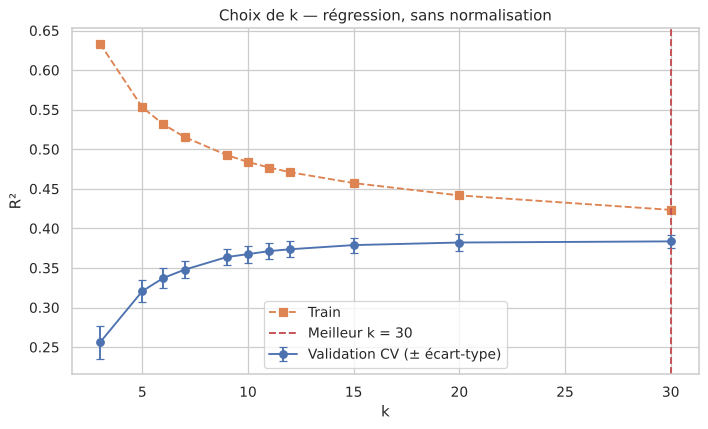

In [ ]:
k_reg = [3, 5, 6, 7, 9, 10, 11, 12, 15, 20, 30]   # grille du TP (3..12) + k plus grands pour voir où la courbe s'arrête de monter

grid_raw = GridSearchCV(KNeighborsRegressor(), {'n_neighbors': k_reg}, cv=5, scoring='r2',
                        return_train_score=True, n_jobs=-1).fit(Xr_train, yr_train)
best_k_raw = grid_raw.best_params_['n_neighbors']
print("Meilleur k (sans normalisation) :", best_k_raw)

res = grid_raw.cv_results_
plt.figure(figsize=(9, 5))
plt.errorbar(k_reg, res['mean_test_score'], yerr=res['std_test_score'], marker='o', capsize=3, label='Validation CV (± écart-type)')
plt.plot(k_reg, res['mean_train_score'], '--s', label='Train')
plt.axvline(best_k_raw, color='r', linestyle='--', label=f'Meilleur k = {best_k_raw}')
plt.xlabel('k'); plt.ylabel('R²'); plt.title('Choix de k — régression, sans normalisation')
plt.legend(); plt.show()

## 5.2 Performances et tableau de résultats

In [ ]:
best_raw = grid_raw.best_estimator_
tab = pd.DataFrame({
    'Performance': ['RMSE', 'R²'],
    'Train': [root_mean_squared_error(yr_train, best_raw.predict(Xr_train)), r2_score(yr_train, best_raw.predict(Xr_train))],
    'Test':  [root_mean_squared_error(yr_test,  best_raw.predict(Xr_test)),  r2_score(yr_test,  best_raw.predict(Xr_test))],
}).round(3)
tab

,Performance,Train,Test
0,RMSE,96628.317,101328.073
1,R²,0.428,0.384


**Interprétation.**
- Sur la grille du TP (k de 3 à 12), le meilleur k était **12**, tout au bord de la grille : la courbe montait encore. En élargissant (15, 20, 30), le meilleur k devient **30** et la courbe commence à s'aplatir.
- Résultats (sans normalisation, k = 30) : **R² = 0,428 en train et 0,384 en test**, RMSE = 96 628 (train) et 101 328 (test) dollars NT. Le modèle explique donc **moins de 40 % de la variance** du plafond de crédit : il est **moyennement performant**, pas très bon. Le RMSE (~101 000) est à comparer à un plafond moyen de ~167 000.
- L'écart train/test est modéré (0,044 de R²) : pas de surapprentissage fort, car un grand k lisse les prédictions. Un petit k (3) donnait au contraire un R² de validation d'environ 0,26 seulement.
- Les variables `BILL_AMT*` et `PAY_AMT*` ont des échelles de centaines de milliers alors que `SEX` vaut 0 ou 1 : les distances sont dominées par les montants. D'où la partie suivante.

# 6. Pour aller plus loin

## 6.1 Effet de la normalisation, de la distance et de la pondération
On compare, **sur le même graphique**, 4 configurations (euclidienne / Manhattan × uniforme / distance), toutes dans un `Pipeline` avec `StandardScaler`, puis la version sans normalisation.

Meilleurs paramètres (avec normalisation) : {'knn__metric': 'manhattan', 'knn__n_neighbors': 30, 'knn__weights': 'uniform'}


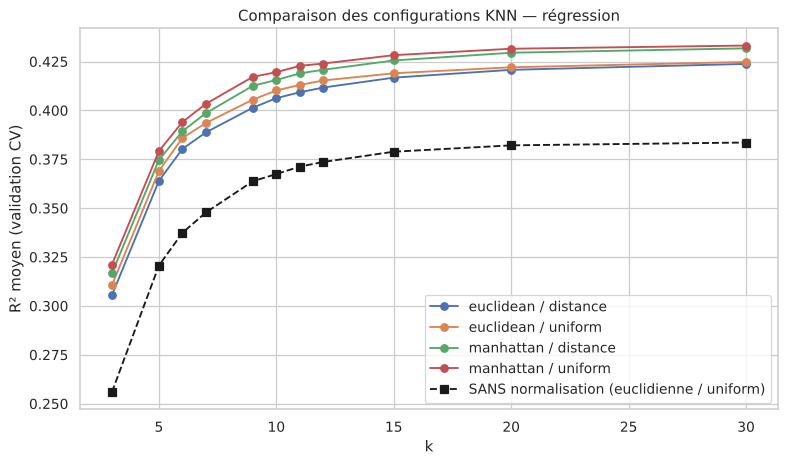

In [ ]:
pipe_reg = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())])
param_reg = {'knn__n_neighbors': k_reg,
             'knn__metric': ['euclidean', 'manhattan'],
             'knn__weights': ['uniform', 'distance']}
grid_reg = GridSearchCV(pipe_reg, param_reg, cv=5, scoring='r2', n_jobs=-1).fit(Xr_train, yr_train)
print("Meilleurs paramètres (avec normalisation) :", grid_reg.best_params_)

cv = pd.DataFrame(grid_reg.cv_results_)
plt.figure(figsize=(10, 5.5))
for (m, w), sub in cv.groupby(['param_knn__metric', 'param_knn__weights']):
    plt.plot(sub['param_knn__n_neighbors'], sub['mean_test_score'], '-o', label=f'{m} / {w}')
plt.plot(k_reg, grid_raw.cv_results_['mean_test_score'], 'k--s', label='SANS normalisation (euclidienne / uniform)')
plt.xlabel('k'); plt.ylabel('R² moyen (validation CV)')
plt.title('Comparaison des configurations KNN — régression'); plt.legend(); plt.show()

In [ ]:
best_reg = grid_reg.best_estimator_
comparaison = pd.DataFrame({
    'Modèle': ['Sans normalisation', 'Avec normalisation + meilleurs paramètres'],
    'RMSE test': [root_mean_squared_error(yr_test, m.predict(Xr_test)) for m in (best_raw, best_reg)],
    'R² test':   [r2_score(yr_test, m.predict(Xr_test)) for m in (best_raw, best_reg)],
    'R² train':  [r2_score(yr_train, m.predict(Xr_train)) for m in (best_raw, best_reg)],
}).round(3)
comparaison

,Modèle,RMSE test,R² test,R² train
0,Sans normalisation,101328.073,0.384,0.428
1,Avec normalisation + meilleurs paramètres,97288.942,0.432,0.473


**Constats.**
- **La normalisation aide nettement** : R² test **0,384 → 0,432** et RMSE test **101 328 → 97 289** (−4 000 environ). Sur le graphique, la courbe en pointillés noirs (sans normalisation) reste en dessous de toutes les autres pour chaque k, d'environ 0,04 de R².
- **Manhattan > euclidienne** : à k égal, les deux courbes Manhattan sont au-dessus des deux euclidiennes. Avec 28 variables, la distance de Manhattan est moins dominée par une seule variable très écartée.
- **`weights='distance'` vs `'uniform'`** : écart minime (de l'ordre de 0,001 à 0,005 de R² selon k). Le meilleur modèle reste **Manhattan / uniform / k = 30** (R² CV ≈ 0,43).
- Dans notre cas, **tous les réglages gagnent peu** par rapport à la normalisation : le R² plafonne autour de 0,43, ce qui suggère que le plafond de crédit dépend aussi de facteurs absents de la base (revenu, ancienneté…) : c'est une hypothèse, pas un résultat mesuré.
- ⚠️ Le meilleur k est encore au bord de la grille (30) : la courbe est presque plate, donc on gagnerait très peu à aller plus loin.

## 6.2 Même comparaison en classification

Meilleurs paramètres (F1) : {'knn__metric': 'euclidean', 'knn__n_neighbors': 15, 'knn__weights': 'uniform'}
Test — exactitude : 0.806 | rappel : 0.314 | F1 : 0.418


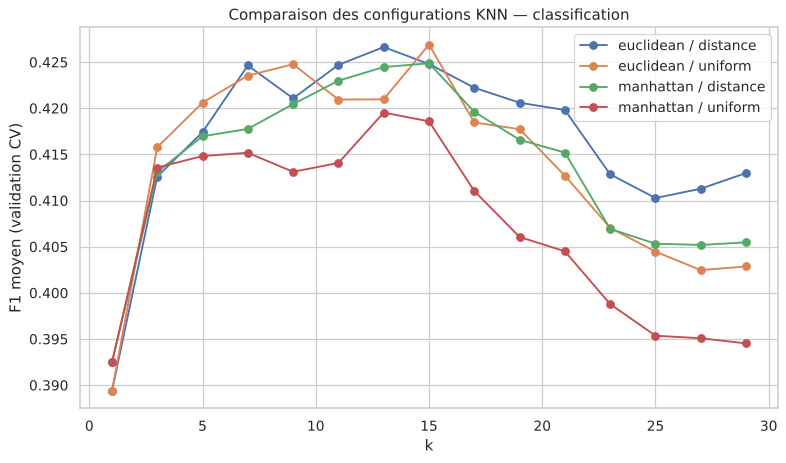

In [ ]:
param_clf = {'knn__n_neighbors': k_values[::2],
             'knn__metric': ['euclidean', 'manhattan'],
             'knn__weights': ['uniform', 'distance']}
grid_clf2 = GridSearchCV(pipe_clf, param_clf, cv=5, scoring='f1', n_jobs=-1).fit(X_train, y_train)
print("Meilleurs paramètres (F1) :", grid_clf2.best_params_)

cv2 = pd.DataFrame(grid_clf2.cv_results_)
plt.figure(figsize=(10, 5.5))
for (m, w), sub in cv2.groupby(['param_knn__metric', 'param_knn__weights']):
    plt.plot(sub['param_knn__n_neighbors'], sub['mean_test_score'], '-o', label=f'{m} / {w}')
plt.xlabel('k'); plt.ylabel('F1 moyen (validation CV)')
plt.title('Comparaison des configurations KNN — classification'); plt.legend(); plt.show()

y_pred2 = grid_clf2.best_estimator_.predict(X_test)
print("Test — exactitude : {:.3f} | rappel : {:.3f} | F1 : {:.3f}".format(
    accuracy_score(y_test, y_pred2), recall_score(y_test, y_pred2), f1_score(y_test, y_pred2)))

# 7. Questions de cours
1. **B** — K est le nombre de voisins les plus proches à considérer.
2. **Faux** — KNN sert aussi à la régression (partie 5).
3. **A** — Sans normalisation, les variables à grande échelle (ici `BILL_AMT*`, `PAY_AMT*`) dominent le calcul des distances (voir partie 6.1).

# Conclusion
**Meilleurs paramètres retenus**
- Classification : `StandardScaler` + KNN, **k = 15** (euclidienne, uniform). Exactitude test 80,6 % contre 77,9 % pour la baseline ; F1 défaut 0,42 ; rappel défaut 0,31.
- Régression (`LIMIT_BAL`) : `StandardScaler` + KNN, **k = 30, Manhattan, uniform**. R² test 0,432 et RMSE test 97 289 (sans normalisation : 0,384 et 101 328).

**Ce qu'on retient**
1. **La normalisation est indispensable** pour KNN (gain net de R² en régression).
2. **Le surapprentissage se contrôle avec k** : k = 1 donne 100 % en train mais 73 % en validation ; il disparaît vers k ≈ 9–15. On le détecte en traçant train et validation sur la même courbe.
3. **L'exactitude seule est trompeuse** quand les classes sont déséquilibrées (78 % / 22 %) : le KNN ne détecte que 31 % des défauts.
4. **Limites de KNN** : lent sur de grandes bases (la grille de recherche a pris plusieurs minutes), sensible à l'échelle, peu adapté aux classes déséquilibrées. Des pistes : pondérer les classes, rééquilibrer l'échantillon, ou comparer à un SVM ou à un arbre.